# Breakout / trend-following system on a halal universe

This is a different kind of backtest from the other notebooks in this project: instead of
cross-sectionally ranking the halal universe once a month, it trades each stock independently on
its own daily signal, in the spirit of the classic Donchian-channel "Turtle Trading" system.
Tickers come from `equities-list.csv` (rows with `Asset Type == Stock`; the ETFs in that file are
excluded). The CSV labels these as halal *candidates* only — independently verify current Shariah
compliance before investing.

**Strategy specification**

- **Entry** — buy when a stock's close breaks above its own trailing 55-day high:
  $$ \text{Close}_t > \max(\text{High}_{t-1}, \dots, \text{High}_{t-55}) $$
- **Stop** — a protective stop set at entry, 3&times; the 20-day Average True Range below the
  entry price: $ \text{Stop} = \text{Entry} - 3 \times \text{ATR}_{20} $. This stop is fixed at
  entry, not trailed.
- **Exit** — sell if the stop is hit intraday (trailing stop breach) *or* the close falls below
  the trailing 20-day low, whichever comes first:
  $$ \text{Close}_t < \min(\text{Low}_{t-1}, \dots, \text{Low}_{t-20}) $$
- **Position management** — long only, one position per name at a time (no pyramiding/adding to
  winners), up to 15 concurrent positions, each sized as an equal share of current portfolio value
  at the moment it's entered. If more than 15 stocks would qualify to enter on the same day, the
  strongest breakouts (furthest above their 55-day high, as a fraction) get the open slots first.

This is a genuinely different backtest engine from the cross-sectional notebooks: trades happen on
whatever day a signal fires, not on a monthly calendar, so this notebook runs a daily event-driven
simulation rather than a monthly rebalance loop. The daily OHLC bars needed for the Donchian
channels and ATR are already present in the shared `data/daily/{TICKER}.csv` cache (the other
notebooks only used the close column, but the full OHLC bars were cached from the start).

## Before running

1. Install dependencies: `pip install ib-insync pandas numpy matplotlib pandas-datareader`
2. Run IBKR Trader Workstation or IB Gateway, enable API connections, and use a market-data-enabled
   account.
3. Set the host, port, and client ID below. Typical paper ports are 7497 for TWS and 4002 for
   Gateway; live ports are commonly 7496 and 4001.
4. Run the acquisition cell once. It shares the same `data/daily/{TICKER}.csv` cache as the other
   momentum notebooks, so if you've already run one of those, this one has nothing left to fetch.

In [1]:
from pathlib import Path
import csv
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from ib_insync import IB, Stock, util
except ImportError as exc:
    raise ImportError('Install ib-insync first: pip install ib-insync') from exc

EQUITIES_LIST_PATH = Path('equities-list.csv')
DATA_DIR = Path('data') / 'daily'
LOG_PATH = Path('data') / 'daily_download_log.csv'

with open(EQUITIES_LIST_PATH, newline='') as f:
    equities_rows = list(csv.DictReader(f))
UNIVERSE = [row['Ticker'] for row in equities_rows if row['Asset Type'] == 'Stock']
print(f'{len(UNIVERSE)} candidate halal stocks in the universe')

EXCHANGE = 'SMART'
CURRENCY = 'USD'
START_DATE = pd.Timestamp('2009-01-01', tz='UTC')
END_DATE = pd.Timestamp.now(tz='UTC')
BAR_SIZE = '1 day'
DURATION = '20 Y'
WHAT_TO_SHOW = 'TRADES'
USE_RTH = True

IB_HOST = '172.27.224.1'  # '127.0.0.1'
IB_PORT = 7497
IB_CLIENT_ID = 35
PACING_SLEEP_SECONDS = 10.0

# Strategy parameters
ENTRY_LOOKBACK_DAYS = 55   # breakout channel
EXIT_LOOKBACK_DAYS = 20    # trend-exit channel
ATR_PERIOD = 20            # ATR window
ATR_STOP_MULT = 3.0        # stop distance, in ATRs below entry
MAX_POSITIONS = 15         # concurrent position cap

INVESTMENT_2026_DOLLARS = 150.0
TARGET_CPI = None  # leave None to use the latest available CPI reading from FRED

132 candidate halal stocks in the universe


## Download or load the daily bars

Identical acquisition logic to the other momentum notebooks: one IBKR historical data request per
ticker (daily bars support multi-year durations in a single call), cached to
`data/daily/{TICKER}.csv`, skipping anything already cached and logged `ok` in
`data/daily_download_log.csv`. This notebook needs the full OHLC columns already present in that
cache, not just the close.

In [2]:
def normalize_bars(bars):
    frame = util.df(bars)
    if frame is None or frame.empty:
        return pd.DataFrame()
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.set_index('date').sort_index()
    keep = ['open', 'high', 'low', 'close', 'volume', 'average', 'barCount']
    return frame[[column for column in keep if column in frame.columns]]

def load_cached_bars(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

def download_universe():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    util.patchAsyncio()
    ib = IB()
    ib.connect(IB_HOST, IB_PORT, clientId=IB_CLIENT_ID, readonly=True, timeout=20)

    log_rows = list(csv.DictReader(open(LOG_PATH))) if LOG_PATH.exists() else []
    done = {row['ticker'] for row in log_rows if row['status'] == 'ok'}

    for i, ticker in enumerate(UNIVERSE, 1):
        cache_path = DATA_DIR / f'{ticker}.csv'
        if ticker in done and cache_path.exists():
            continue
        status, n_bars, first_date, last_date, error = 'ok', 0, '', '', ''
        try:
            contract = Stock(ticker, EXCHANGE, CURRENCY)
            qualified = ib.qualifyContracts(contract)
            if not qualified or contract.conId == 0:
                raise RuntimeError('contract could not be qualified')
            bars = ib.reqHistoricalData(
                contract, endDateTime='', durationStr=DURATION,
                barSizeSetting=BAR_SIZE, whatToShow=WHAT_TO_SHOW,
                useRTH=USE_RTH, formatDate=2, keepUpToDate=False,
            )
            frame = normalize_bars(bars)
            if frame.empty:
                status = 'no_data'
            else:
                frame.to_csv(cache_path, index_label='date')
                n_bars = len(frame)
                first_date, last_date = str(frame.index.min().date()), str(frame.index.max().date())
        except Exception as exc:
            status, error = 'error', str(exc)
        print(f'[{i}/{len(UNIVERSE)}] {ticker}: {status} n_bars={n_bars} {first_date}..{last_date} {error}')
        log_rows = [r for r in log_rows if r['ticker'] != ticker]
        log_rows.append({'ticker': ticker, 'status': status, 'n_bars': n_bars,
                          'first_date': first_date, 'last_date': last_date, 'error': error})
        with open(LOG_PATH, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=['ticker', 'status', 'n_bars', 'first_date', 'last_date', 'error'])
            writer.writeheader()
            writer.writerows(log_rows)
        time.sleep(PACING_SLEEP_SECONDS)

    ib.disconnect()

missing = [t for t in UNIVERSE if not (DATA_DIR / f'{t}.csv').exists()]
if missing:
    print(f'{len(missing)} tickers not yet cached, downloading from IBKR...')
    download_universe()
else:
    print('All tickers already cached.')

All tickers already cached.


## Build the OHLC panels and the signals

Three wide daily panels (high, low, close), then the Donchian channels and ATR computed
vectorized across the whole universe at once:

- `donchian_high` — the trailing 55-day high, shifted by one day so today's entry decision only
  ever looks at *prior* days.
- `donchian_low` — the trailing 20-day low, same shift, used for the trend-exit.
- `atr` — 20-day average true range, the standard three-way true range (today's high/low range,
  or the gap from yesterday's close, whichever is larger).
- `entry_signal` — today's close above the (shifted) 55-day high.

In [3]:
daily_bars = {}
for ticker in UNIVERSE:
    cache_path = DATA_DIR / f'{ticker}.csv'
    if not cache_path.exists():
        continue
    bars = load_cached_bars(ticker)
    if bars.empty:
        continue
    daily_bars[ticker] = bars

high_panel = pd.DataFrame({t: b['high'] for t, b in daily_bars.items()}).sort_index()
low_panel = pd.DataFrame({t: b['low'] for t, b in daily_bars.items()}).sort_index()
close_panel = pd.DataFrame({t: b['close'] for t, b in daily_bars.items()}).sort_index()

high_panel = high_panel.loc[high_panel.index >= START_DATE]
low_panel = low_panel.reindex(high_panel.index)
close_panel = close_panel.reindex(high_panel.index)

print(f'{close_panel.shape[1]} tickers, {close_panel.shape[0]} trading days '
      f'from {close_panel.index.min().date()} to {close_panel.index.max().date()}')

prev_close = close_panel.shift(1)
true_range = np.maximum(np.maximum(high_panel - low_panel, (high_panel - prev_close).abs()),
                         (low_panel - prev_close).abs())
atr = true_range.rolling(ATR_PERIOD, min_periods=ATR_PERIOD).mean()

donchian_high = high_panel.rolling(ENTRY_LOOKBACK_DAYS, min_periods=ENTRY_LOOKBACK_DAYS).max().shift(1)
donchian_low = low_panel.rolling(EXIT_LOOKBACK_DAYS, min_periods=EXIT_LOOKBACK_DAYS).min().shift(1)
entry_signal = close_panel > donchian_high

132 tickers, 4450 trading days from 2009-01-02 to 2026-09-11


## Daily event-driven backtest

Unlike the monthly notebooks, this walks forward one trading day at a time: process exits first
(a stop-loss breach takes priority over a channel exit on the same day), mark the portfolio to
market, then fill any open slots with the day's strongest new breakouts. Converting the signal
frames to plain numpy arrays first keeps ~4,400 trading days x ~130 tickers fast — the whole loop
runs in well under a second.

In [4]:
dates = close_panel.index
tickers = close_panel.columns.tolist()
ticker_idx = {t: j for j, t in enumerate(tickers)}
n_dates = len(dates)

close_v = close_panel.values
low_v = low_panel.values
atr_v = atr.values
donch_low_v = donchian_low.values
donch_high_v = donchian_high.values
entry_v = entry_signal.values

positions = {}
cash = 1.0
nav_history = np.empty(n_dates)
trade_log = []

for i in range(n_dates):
    # 1. Exits: a stop-loss breach takes priority over a channel exit the same day.
    to_remove = []
    for tkr, pos in positions.items():
        j = ticker_idx[tkr]
        c = close_v[i, j]
        if np.isnan(c):
            continue
        lo = low_v[i, j]
        exit_price, exit_reason = None, None
        if not np.isnan(lo) and lo <= pos['stop']:
            exit_price, exit_reason = pos['stop'], 'stop'
        else:
            dlow = donch_low_v[i, j]
            if not np.isnan(dlow) and c < dlow:
                exit_price, exit_reason = c, 'channel'
        if exit_price is not None:
            cash += pos['shares'] * exit_price
            trade_log.append({
                'ticker': tkr, 'entry_date': pos['entry_date'], 'entry_price': pos['entry_price'],
                'exit_date': dates[i], 'exit_price': exit_price, 'exit_reason': exit_reason,
                'return_pct': (exit_price / pos['entry_price'] - 1.0) * 100,
                'holding_days': (dates[i] - pos['entry_date']).days,
            })
            to_remove.append(tkr)
    for tkr in to_remove:
        del positions[tkr]

    open_value = sum(positions[t]['shares'] * close_v[i, ticker_idx[t]] for t in positions
                      if not np.isnan(close_v[i, ticker_idx[t]]))
    nav_at_entry_phase = cash + open_value

    # 2. Entries: rank same-day candidates by breakout strength, fill open slots.
    free_slots = MAX_POSITIONS - len(positions)
    if free_slots > 0:
        candidates = []
        for j, tkr in enumerate(tickers):
            if tkr in positions:
                continue
            if (entry_v[i, j] and not np.isnan(atr_v[i, j]) and not np.isnan(close_v[i, j])
                    and close_v[i, j] > 0 and atr_v[i, j] > 0):
                strength = close_v[i, j] / donch_high_v[i, j] - 1.0
                candidates.append((strength, tkr, j))
        candidates.sort(reverse=True)
        for strength, tkr, j in candidates[:free_slots]:
            if cash <= 0:
                break  # no cash left to deploy this day, regardless of open slots
            alloc = min(nav_at_entry_phase / MAX_POSITIONS, cash)
            entry_price = close_v[i, j]
            shares = alloc / entry_price
            stop = entry_price - ATR_STOP_MULT * atr_v[i, j]
            positions[tkr] = {'shares': shares, 'stop': stop, 'entry_price': entry_price, 'entry_date': dates[i]}
            cash -= alloc

    open_value = sum(positions[t]['shares'] * close_v[i, ticker_idx[t]] for t in positions
                      if not np.isnan(close_v[i, ticker_idx[t]]))
    nav_history[i] = cash + open_value

nav = pd.Series(nav_history, index=dates)
trades = pd.DataFrame(trade_log)
print(f'{len(trades):,} completed trades, {len(positions)} open positions as of {dates[-1].date()}')

1,319 completed trades, 14 open positions as of 2026-09-11


### Current open positions

Whatever the system is holding as of the last cached trading day — the same shape as the "latest
holdings" table in the other notebooks, but here it's a live snapshot of an always-on system
rather than a monthly rebalance.

In [5]:
last_i = n_dates - 1
open_rows = []
for tkr, pos in positions.items():
    j = ticker_idx[tkr]
    current_price = close_v[last_i, j]
    open_rows.append({
        'ticker': tkr,
        'entry_date': pos['entry_date'].date(),
        'entry_price': round(pos['entry_price'], 2),
        'current_price': round(current_price, 2) if not np.isnan(current_price) else None,
        'unrealized_pct': round((current_price / pos['entry_price'] - 1) * 100, 1) if not np.isnan(current_price) else None,
        'stop_price': round(pos['stop'], 2),
        'pct_to_stop': round((current_price / pos['stop'] - 1) * 100, 1) if not np.isnan(current_price) else None,
    })
open_positions_table = pd.DataFrame(open_rows).sort_values('unrealized_pct', ascending=False)
display(open_positions_table)

,ticker,entry_date,entry_price,current_price,unrealized_pct,stop_price,pct_to_stop
1,CRWD,2026-05-18,154.71,206.74,33.6,137.52,50.3
5,MPC,2026-07-14,303.40,395.93,30.5,277.91,42.5
0,TGT,2026-03-03,120.80,155.83,29.0,109.60,42.2
6,VLO,2026-07-20,313.31,390.42,24.6,281.73,38.6
2,ABBV,2026-06-05,227.23,257.12,13.2,211.01,21.9
4,ANET,2026-07-09,184.69,199.59,8.1,155.83,28.1
8,NEM,2026-08-10,117.26,126.81,8.1,105.51,20.2
3,JNJ,2026-06-26,254.66,265.58,4.3,237.88,11.6
11,GOLD,2026-09-08,47.47,48.22,1.6,40.42,19.3
13,DVN,2026-09-10,50.02,50.23,0.4,46.34,8.4


## Trade statistics

This is "more of a trading strategy," so its natural scoreboard is trade-level, not just monthly
returns: how many trades, how often they win, and by how much when they do versus when they
don't. Classic trend-following systems tend to have a win rate under 50% with a much larger
average winner than average loser — that's the payoff shape to look for here, not a high hit
rate.

In [6]:
trade_stats = pd.Series({
    'total_trades': len(trades),
    'win_rate': float((trades['return_pct'] > 0).mean()),
    'avg_win_pct': float(trades.loc[trades['return_pct'] > 0, 'return_pct'].mean()),
    'avg_loss_pct': float(trades.loc[trades['return_pct'] <= 0, 'return_pct'].mean()),
    'avg_holding_days': float(trades['holding_days'].mean()),
    'best_trade_pct': float(trades['return_pct'].max()),
    'worst_trade_pct': float(trades['return_pct'].min()),
    'profit_factor': float(
        trades.loc[trades['return_pct'] > 0, 'return_pct'].sum()
        / -trades.loc[trades['return_pct'] <= 0, 'return_pct'].sum()
    ),
})
display(trade_stats.to_frame('value'))
display(trades['exit_reason'].value_counts().to_frame('trade_count'))

,value
total_trades,1319.000000
win_rate,0.415466
avg_win_pct,16.334472
avg_loss_pct,-5.737287
avg_holding_days,65.711903
best_trade_pct,216.464646
worst_trade_pct,-23.915592
profit_factor,2.023600


,trade_count
exit_reason,
channel,896
stop,423


## General statistics

Same shape of summary as the other notebooks, computed from the daily NAV series (this strategy
trades on daily signals, so daily-frequency stats are the more natural fit here, unlike the
monthly-rebalance notebooks).

In [7]:
def max_drawdown(wealth):
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

daily_returns = nav.pct_change().dropna()
start_date, end_date = nav.index[0], nav.index[-1]
years = (end_date - start_date).days / 365.2425
total_return = float(nav.iloc[-1] - 1.0)
cagr = float(nav.iloc[-1] ** (1 / years) - 1.0)
annualized_volatility = float(daily_returns.std() * np.sqrt(252))
sharpe_rf0 = float((daily_returns.mean() * 252) / annualized_volatility) if annualized_volatility else float('nan')

stats = pd.Series({
    'start': start_date,
    'end': end_date,
    'trading_days': len(nav),
    'total_return': total_return,
    'CAGR': cagr,
    'annualized_volatility': annualized_volatility,
    'sharpe_ratio_rf0': sharpe_rf0,
    'max_drawdown': max_drawdown(nav),
    'final_wealth_multiple': float(nav.iloc[-1]),
})
display(stats.to_frame('value'))

,value
start,2009-01-02 00:00:00+00:00
end,2026-09-11 00:00:00+00:00
trading_days,4450
total_return,14.344959
CAGR,0.166925
annualized_volatility,0.179202
sharpe_ratio_rf0,0.953271
max_drawdown,-0.242212
final_wealth_multiple,15.344959


## Buy-and-hold-style dollar simulation

Same purchasing-power framing as the other notebooks: size a 2009-era investment so it has the
same purchasing power as $150 today (via FRED CPI), run it through this strategy's compounded
return, and compare the ending value against today's $150 in real terms. This is a price-only,
no-cost simulation, and this notebook in particular assumes stop and channel exits fill at exactly
their trigger price with no slippage — see caveats.

In [8]:
try:
    from pandas_datareader import data as web
    cpi = web.DataReader('CPIAUCSL', 'fred', '2008-12-01', pd.Timestamp.now())['CPIAUCSL'].dropna()
    cpi_2009 = float(cpi.loc[cpi.index >= '2009-01-01'].iloc[0])
    target_cpi = float(TARGET_CPI) if TARGET_CPI is not None else float(cpi.iloc[-1])
    cpi_source = 'FRED CPIAUCSL'
except Exception as exc:
    if TARGET_CPI is None:
        raise RuntimeError('FRED CPI retrieval failed. Set TARGET_CPI to a CPIAUCSL value for the target dollar period.') from exc
    cpi_2009 = 211.143
    target_cpi = float(TARGET_CPI)
    cpi_source = 'manual target CPI; Jan 2009 CPI fallback'

initial_2009_dollars = INVESTMENT_2026_DOLLARS * cpi_2009 / target_cpi
ending_value = initial_2009_dollars * nav.iloc[-1]
nominal_gain = ending_value - initial_2009_dollars
real_gain_vs_target_dollars = ending_value - INVESTMENT_2026_DOLLARS
real_multiple_vs_target_dollars = ending_value / INVESTMENT_2026_DOLLARS

simulation = pd.Series({
    'target_dollars': INVESTMENT_2026_DOLLARS,
    'cpi_2009': cpi_2009,
    'target_cpi': target_cpi,
    'initial_investment_in_2009_dollars': initial_2009_dollars,
    'ending_nominal_value': ending_value,
    'nominal_gain': nominal_gain,
    'total_return': total_return,
    'CAGR': cagr,
    'ending_value_in_target_dollars': ending_value,
    'real_gain_vs_target_dollars': real_gain_vs_target_dollars,
    'real_multiple_vs_target_dollars': real_multiple_vs_target_dollars,
})
print(f'CPI source: {cpi_source}')
display(simulation.to_frame('value'))

CPI source: FRED CPIAUCSL


,value
target_dollars,150.000000
cpi_2009,211.933000
target_cpi,334.131000
initial_investment_in_2009_dollars,95.142175
ending_nominal_value,1459.952735
nominal_gain,1364.810560
total_return,14.344959
CAGR,0.166925
ending_value_in_target_dollars,1459.952735
real_gain_vs_target_dollars,1309.952735


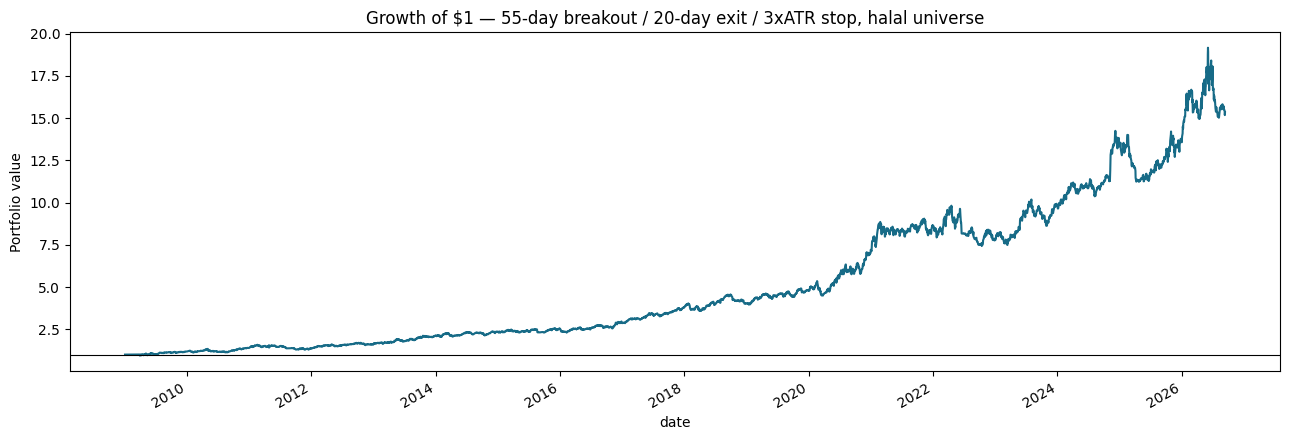

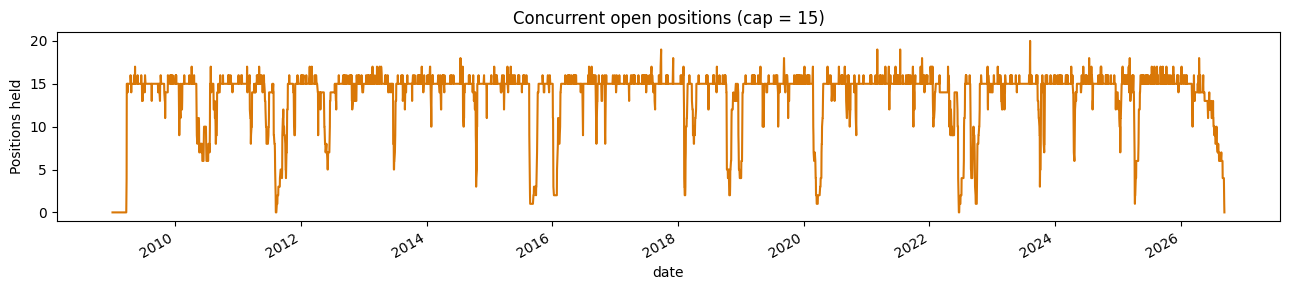

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.5))
nav.plot(ax=ax, color='#176b87', title='Growth of $1 — 55-day breakout / 20-day exit / 3xATR stop, halal universe')
ax.set_ylabel('Portfolio value')
ax.axhline(1, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 3))
open_count = pd.Series(0, index=dates)
for t in trades.itertuples():
    open_count.loc[t.entry_date:t.exit_date] += 1
open_count.plot(ax=ax, color='#d97706', title=f'Concurrent open positions (cap = {MAX_POSITIONS})')
ax.set_ylabel('Positions held')
plt.tight_layout()
plt.show()

## Monthly performance

The daily NAV series resampled to month-end, so this strategy can be read on the same monthly
heatmap as the other notebooks even though it actually trades on daily signals.

In [10]:
monthly_nav = nav.resample('ME').last()
today_ts = pd.Timestamp.now(tz='UTC')
if len(monthly_nav) and (monthly_nav.index[-1].year, monthly_nav.index[-1].month) == (today_ts.year, today_ts.month):
    monthly_nav = monthly_nav.iloc[:-1]
monthly_returns = monthly_nav.pct_change().dropna()

table = (monthly_returns * 100).rename('ret').to_frame()
table['year'] = table.index.year
table['month'] = table.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_table = table.pivot(index='year', columns='month', values='ret').reindex(columns=month_order)

annual_return = monthly_returns.groupby(monthly_returns.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
monthly_table['Year'] = annual_return

monthly_summary = pd.Series({
    'months': len(monthly_returns),
    'positive_months': int((monthly_returns > 0).sum()),
    'pct_positive_months': float((monthly_returns > 0).mean()),
    'avg_monthly_return': float(monthly_returns.mean()),
    'median_monthly_return': float(monthly_returns.median()),
    'best_month': monthly_returns.idxmax().strftime('%Y-%m'),
    'best_month_return': float(monthly_returns.max()),
    'worst_month': monthly_returns.idxmin().strftime('%Y-%m'),
    'worst_month_return': float(monthly_returns.min()),
})

styled = (
    monthly_table.round(1)
    .style.format(precision=1, na_rep='')
    .background_gradient(cmap='RdYlGn', axis=None, vmin=-15, vmax=15, subset=month_order)
    .set_caption('Monthly return (%) by year')
)
display(styled)
display(monthly_summary.to_frame('value'))

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year
year,,,,,,,,,,,,,
2009,,0.0,-5.2,8.0,1.2,-0.9,8.0,1.3,0.4,-2.7,4.8,2.7,18.0
2010,-1.8,-0.4,4.9,7.9,-7.5,-3.8,-0.3,-1.2,8.2,6.2,2.0,3.6,18.0
2011,7.1,3.0,-1.3,-0.2,2.2,-3.7,-3.1,-4.8,-4.6,2.6,-1.1,1.8,-2.7
2012,5.8,3.8,4.1,1.5,-4.0,3.5,0.7,3.3,2.4,-2.0,-1.4,-0.2,18.5
2013,4.5,-0.3,4.5,-0.3,7.0,-4.2,4.9,-0.4,7.3,3.2,-0.9,4.6,33.2
2014,-1.4,5.6,-4.4,-0.2,2.0,6.5,-4.3,4.1,-1.5,-2.3,7.0,-1.3,9.3
2015,-1.0,5.3,-1.6,-3.2,2.2,-0.3,4.8,-6.3,-0.7,6.6,3.2,-0.7,7.6
2016,-6.5,2.7,4.0,3.1,-3.4,2.1,5.8,-0.5,-1.0,-2.2,9.2,0.5,13.8
2017,3.6,3.8,2.2,-0.1,5.7,0.4,-0.0,2.2,1.0,4.2,4.4,1.0,32.0


,value
months,211
positive_months,127
pct_positive_months,0.601896
avg_monthly_return,0.014323
median_monthly_return,0.015365
best_month,2024-11
best_month_return,0.196058
worst_month,2026-07
worst_month_return,-0.165316


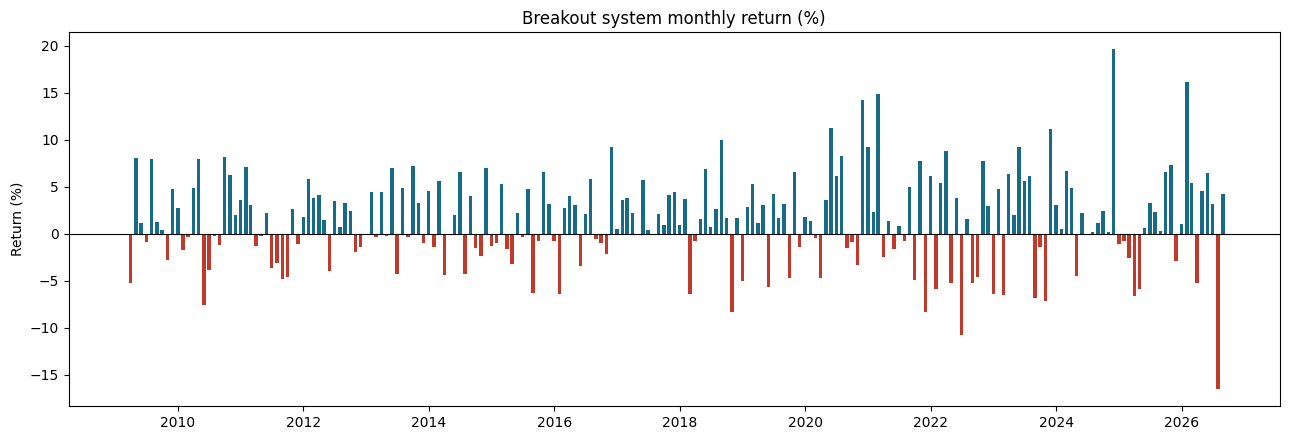

In [11]:
colors = np.where(monthly_returns >= 0, '#176b87', '#c0392b')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(monthly_returns.index, monthly_returns.values * 100, width=20, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Breakout system monthly return (%)')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()

## Caveats and next improvements

- **No slippage or gaps**: stops and channel exits are assumed to fill at exactly their trigger
  price. In practice a stock gapping down through its stop overnight fills *worse* than the stop
  price — this is the single biggest way this backtest is optimistic, more so than the monthly
  notebooks, since a fast-moving breakout/breakdown system is exactly the kind of strategy gap
  risk hurts most.
- **No transaction costs**: 1,300+ trades over the backtest window means commissions and spread
  matter a lot here — more trades than any of the cross-sectional notebooks.
- **Same-bar signal and fill**: entry uses today's close to both trigger *and* fill the trade,
  and exits similarly assume the trigger price is achievable. A live system only knows the close
  once the market has closed.
- **No pyramiding**: real trend-following systems (including the original Turtle rules) often add
  to a winning position as it extends; this notebook opens exactly one unit per name and lets it
  ride to its exit.
- **Equal-weight-of-NAV sizing, not volatility-based**: the classic Turtle system sizes each entry
  so that hitting the stop loses a fixed fraction of capital (a smaller position in a more volatile
  name). This notebook instead gives every one of the 15 slots an equal dollar amount regardless of
  ATR, which is simpler but means a volatile breakout risks more capital than a quiet one. Sizing is
  cash-constrained — a new entry never spends more than what's actually sitting in cash, even if the
  1/15-of-NAV target momentarily exceeds it (e.g. right after existing positions have run up).
- **Fixed, non-trailing stop**: the stop is set once at entry and never moves up as a position
  gains. A trailing-stop variant (recompute `close - 3*ATR` and only ratchet it upward) is a
  common, easy extension.
- **20-day-low exit only**: the alternative mentioned in the original spec — exiting on a break
  below the 50-day moving average — isn't implemented here, but would be a one-line swap for the
  channel-exit condition.
- **Look-ahead / survivorship bias in the universe**: `equities-list.csv` is today's list of halal
  candidates, projected backward, same caveat as every other notebook in this project.
- A serious version of this strategy would need realistic slippage assumptions (especially around
  gap risk), volatility-based position sizing, and probably a comparison of trailing vs. fixed
  stops before trusting the backtest's drawdown numbers.